# Data Science Challenge Hackathon 2026

## Section 1: Introduction

This project aims to predict seasonal influenza vaccination uptake using machine learning.

The objective is to develop and compare predictive models while considering the financial costs of vaccination and hospitalisation.

**Target Variable:** seasonal_vaccine

**Dataset:** Dataset A

**Approach:** Exploratory Data Analysis, Data Preprocessing, Machine Learning, Model Evaluation and Cost Analysis.

## IMPORTING REQUIRED LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

print("Libraries imported successfully!")

Libraries imported successfully!


## UPLOADING REQUIRED DATASETS

In [2]:
from google.colab import files

uploaded = files.upload()

Saving dataset_A_example_submission.csv to dataset_A_example_submission.csv
Saving dataset_A_testing.csv to dataset_A_testing.csv
Saving dataset_A_training.csv to dataset_A_training.csv


In [3]:
train_df = pd.read_csv("dataset_A_training.csv")
test_df = pd.read_csv("dataset_A_testing.csv")

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

display(train_df.head())

Training dataset: (4756, 31)
Testing dataset: (4749, 30)


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


## DATASET EXPLORATION

In [4]:
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("\nTraining Dataset Information:")
train_df.info()

Training Dataset Shape: (4756, 31)
Testing Dataset Shape: (4749, 30)

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   flu_concern                    4744 non-null   float64
 2   flu_knowledge                  4733 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4724 non-null   float64
 5   behavioral_face_mask           4753 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4747 non-null   float64
 9   behavioral_touch_face          4737 non-null   float64
 10  doctor_recc_seasonal           4435 non-null   float64
 11  child_un

In [5]:
print("Missing Values in Training Dataset:")
display(train_df.isnull().sum())

print("\nMissing Values in Testing Dataset:")
display(test_df.isnull().sum())

Missing Values in Training Dataset:


,0
respondent_id,0
flu_concern,12
flu_knowledge,23
behavioral_antiviral_meds,14
behavioral_avoidance,32
behavioral_face_mask,3
behavioral_wash_hands,8
behavioral_large_gatherings,9
behavioral_outside_home,9
behavioral_touch_face,19



Missing Values in Testing Dataset:


,0
respondent_id,0
flu_concern,21
flu_knowledge,18
behavioral_antiviral_meds,14
behavioral_avoidance,47
behavioral_face_mask,3
behavioral_wash_hands,6
behavioral_large_gatherings,27
behavioral_outside_home,12
behavioral_touch_face,30


In [6]:
print("Duplicate Rows in Training:", train_df.duplicated().sum())
print("Duplicate Rows in Testing:", test_df.duplicated().sum())

Duplicate Rows in Training: 0
Duplicate Rows in Testing: 0


Seasonal Vaccine Distribution:
seasonal_vaccine
1    2551
0    2205
Name: count, dtype: int64


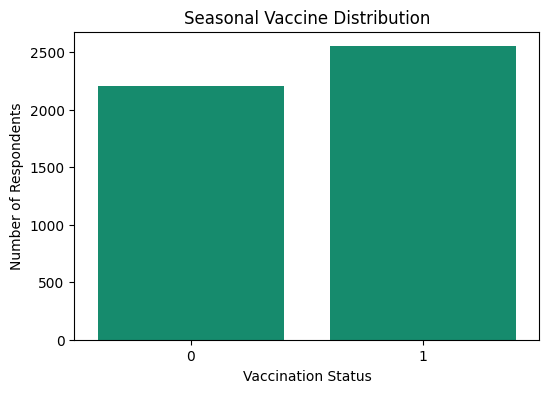

In [7]:
print("Seasonal Vaccine Distribution:")
print(train_df["seasonal_vaccine"].value_counts())

plt.figure(figsize=(6, 4))

sns.countplot(
    data=train_df,
    x="seasonal_vaccine", color="#029f76"
)

plt.title("Seasonal Vaccine Distribution")
plt.xlabel("Vaccination Status")
plt.ylabel("Number of Respondents")
plt.show()

In [8]:
display(train_df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
flu_concern,4744.0,NaN,NaN,NaN,1.643128,0.91981,0.0,1.0,2.0,2.0,3.0
flu_knowledge,4733.0,NaN,NaN,NaN,1.293049,0.618902,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.052299,0.222652,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4724.0,NaN,NaN,NaN,0.734124,0.441846,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4753.0,NaN,NaN,NaN,0.073848,0.261551,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,NaN,NaN,NaN,0.836563,0.369803,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,NaN,NaN,NaN,0.365494,0.481619,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4747.0,NaN,NaN,NaN,0.336634,0.472608,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4737.0,NaN,NaN,NaN,0.68841,0.463192,0.0,0.0,1.0,1.0,1.0


## Dataset Exploration

The training and testing datasets were examined to understand
their structure, data types, missing values, and duplicate records.

The distribution of the target variable, seasonal_vaccine,
was analysed to identify potential class imbalance.

Summary statistics were also generated to understand the
characteristics of the dataset.

These findings will guide the preprocessing and machine
learning stages.